**Projeto de Análise de Dados Exploratória: Segmentação de Clientes e Sistema de Recomendação**:
Este projeto foca na análise de dados de vendas de um retalhista com o objetivo de transformar dados transacionais brutos em conhecimento estratégico. Através da Análise Exploratória de Dados (EDA), pretendemos:

Limpar e preparar os dados para análise.

Criar novas métricas (Engenharia de Features) focadas no comportamento do cliente.

Segmentar os clientes em grupos (Clusters) usando K-Means.

Desenvolver um sistema de recomendação personalizado para cada segmento.


**1. Introdução e Carregamento de Dados:**

Nesta secção, importamos as bibliotecas necessárias e carregamos o dataset de transações de retalho.
O objetivo é realizar uma primeira inspeção para compreender a estrutura das colunas, tipos de dados e volume inicial de registos.

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn

path = "/content/drive/MyDrive/Projeto_ADE/Retalho.csv"
df = pd.read_csv(path, sep=';', encoding='latin1')

df.head()

,N_Fatura,SKU,Descricao,Quantidade,Data_Fatura,Preco_Unitario,Cliente,Pais
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,"2,55",17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,"2,75",17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom


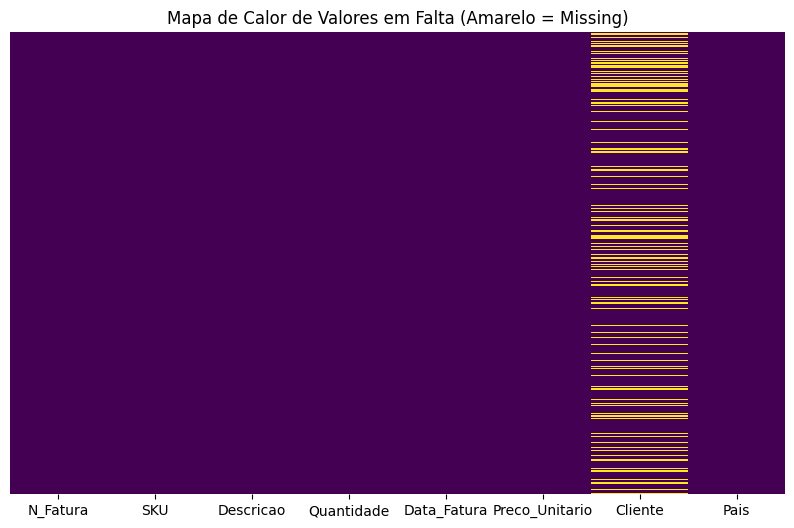

In [70]:
# Visualizar dados em falta (Missing Values)
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Mapa de Calor de Valores em Falta (Amarelo = Missing)')
plt.show()

**Inspeção Inicial e Tipos de Dados:**

Após carregar os dados, é fundamental verificar a estrutura do dataset. De acordo com o enunciado, as variáveis principais incluem N_Fatura, SKU, Quantidade, Data_Fatura, Preco_Unitario e Cliente. Nesta célula, verificamos os tipos de dados e a existência de valores nulos, especialmente na coluna Cliente.

In [15]:
# Verificar tipos de colunas e valores em falta
print("Informações do Dataset:")
df.info()

# Estatísticas descritivas para identificar valores anómalos (ex: preços negativos)
print("\nEstatísticas Descritivas:")
df.describe()

Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   N_Fatura        541909 non-null  object 
 1   SKU             541909 non-null  object 
 2   Descricao       540455 non-null  object 
 3   Quantidade      541909 non-null  int64  
 4   Data_Fatura     541909 non-null  object 
 5   Preco_Unitario  541909 non-null  object 
 6   Cliente         406829 non-null  float64
 7   Pais            541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB

Estatísticas Descritivas:


,Quantidade,Cliente
count,541909.000000,406829.000000
mean,9.552250,15287.690570
std,218.081158,1713.600303
min,-80995.000000,12346.000000
25%,1.000000,13953.000000
50%,3.000000,15152.000000
75%,10.000000,16791.000000
max,80995.000000,18287.000000


In [16]:
df.isna().sum()
#Identificação de valores omissos explícitos (NaN) nas variáveis do dataset.

,0
N_Fatura,0
SKU,0
Descricao,1454
Quantidade,0
Data_Fatura,0
Preco_Unitario,0
Cliente,135080
Pais,0


**2. Limpeza e Pré-processamento**
A qualidade dos dados é crítica para a segmentação. Vamos aplicar um funil de limpeza em 4 etapas:
* **Passo 5:** Remover transações canceladas (código 'C') e erros de stock (quantidades negativas).
* **Passo 6:** Filtrar SKUs de serviços (ex: portes, taxas bancárias), mantendo apenas produtos físicos (códigos de 5 dígitos).
* **Passo 7:** Corrigir descrições manuais e padronizar textos.
* **Passo 8:** Eliminar registos sem valor comercial (preço unitário = 0).

In [17]:
(df['Cliente'].astype(str).str.strip() == '').sum() #Deteção de missing values não explícitos

(df['Descricao'].astype(str).str.strip() == '').sum()

np.int64(0)

In [18]:
#Tratamento de valores omissos:
df[['Cliente', 'Descricao']] = df[['Cliente', 'Descricao']].replace(
    r'^\s*$',
    np.nan,
    regex=True
)

df_1 = df.dropna(subset=['Cliente', 'Descricao'])
df_1.shape


(406829, 8)

In [19]:
#Remoção de duplicados e clientes inválidos
df_1 = df_1[df_1['Cliente'].astype(str).str.strip() != '']
df_2 = df_1.drop_duplicates()
df_2.shape



(401604, 8)

In [20]:
# --- PASSO 5: Eliminar faturas canceladas e quantidades negativas ---
# Filtramos faturas que NÃO começam com 'C' e quantidades estritamente positivas
df_limpo = df_2[~df_2['N_Fatura'].str.startswith('C', na=False)]
df_limpo = df_limpo[df_limpo['Quantidade'] > 0]


In [21]:
# --- PASSO 6: Normalizar SKUs (Manter apenas produtos reais) ---
# Mantém apenas SKUs com 5 dígitos + letra opcional (remove POST, DOT, M, etc.)
df_limpo = df_limpo[df_limpo['SKU'].str.match(r'^[0-9]{5}[a-zA-Z]*$', na=False)]


In [22]:
# --- PASSO 7: Descrições (Eliminar os 83 casos com minúsculas) ---
# Identificamos descrições com letras minúsculas (erros de sistema/manuais)
condicao_minusculas = df_limpo['Descricao'].str.contains(r'[a-z]', na=False)
print(f"Casos com minúsculas encontrados: {condicao_minusculas.sum()}")

# Removemos esses 83 casos e uniformizamos para MAIÚSCULAS
df_limpo = df_limpo[~condicao_minusculas].copy()
df_limpo['Descricao'] = df_limpo['Descricao'].str.upper().str.strip()

Casos com minúsculas encontrados: 1355


In [23]:
# --- PASSO 8: Preço  ---
# Primeiro, converter 'Preco_Unitario' de string (com vírgula) para float
df_limpo['Preco_Unitario'] = df_limpo['Preco_Unitario'].astype(str).str.replace(',', '.').astype(float)

# Identificar e eliminar linhas com preço unitário igual a 0
print(f"Casos com preço zero encontrados: {(df_limpo['Preco_Unitario'] == 0).sum()}") # Deve dar 33
df_limpo = df_limpo[df_limpo['Preco_Unitario'] > 0]


Casos com preço zero encontrados: 33


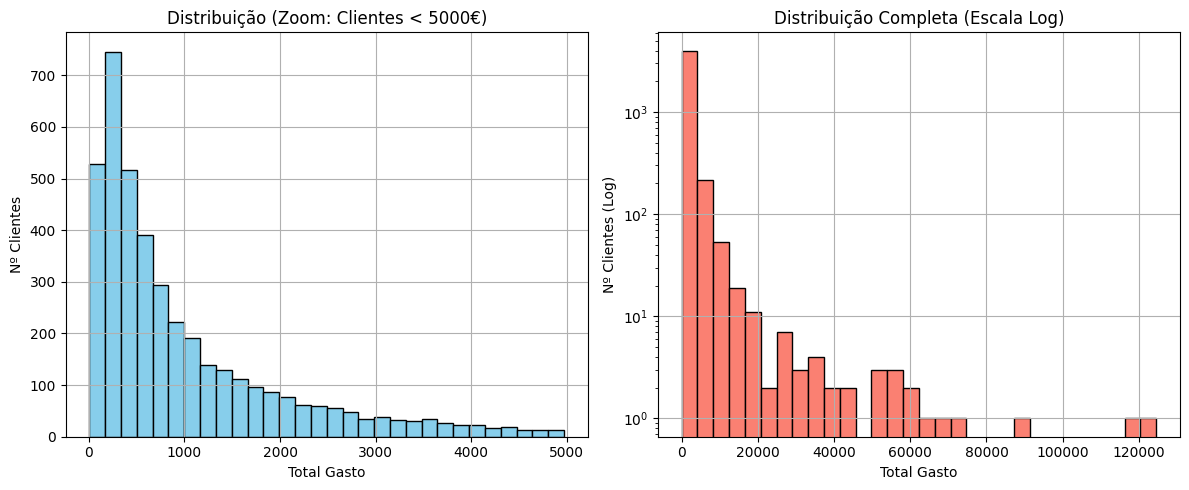

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o tamanho da figura
plt.figure(figsize=(12, 5))

# GRÁFICO 1: ZOOM (Ver apenas quem gasta menos de 5.000€)
# Isto permite ver a distribuição da "população normal"
plt.subplot(1, 2, 1)
limite_visualizacao = 5000
dados_normais = df_clientes[df_clientes['Monetario'] < limite_visualizacao]
dados_normais['Monetario'].hist(bins=30, color='skyblue', edgecolor='black')
plt.title(f'Distribuição (Zoom: Clientes < {limite_visualizacao}€)')
plt.xlabel('Total Gasto')
plt.ylabel('Nº Clientes')

# GRÁFICO 2: ESCALA LOGARÍTMICA
# Isto "comprime" os outliers para podermos ver tudo no mesmo gráfico
plt.subplot(1, 2, 2)
df_clientes['Monetario'].hist(bins=30, color='salmon', edgecolor='black')
plt.yscale('log') # Escala logarítmica no eixo Y
plt.title('Distribuição Completa (Escala Log)')
plt.xlabel('Total Gasto')
plt.ylabel('Nº Clientes (Log)')

plt.tight_layout()
plt.show()

Corte aplicado: Clientes acima de 10566.22€ serão removidos.


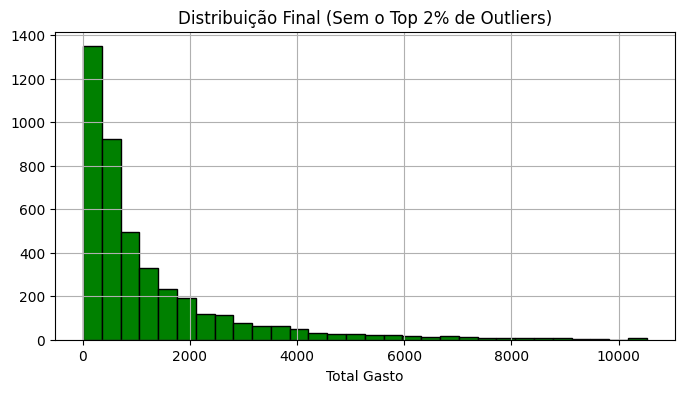

Dimensão final para clustering: (4240, 12)


In [66]:
# Calcular o limite do percentil 98 (98% dos clientes gastam menos que isto)
limite_corte = df_clientes['Monetario'].quantile(0.98)
print(f"Corte aplicado: Clientes acima de {limite_corte:.2f}€ serão removidos.")

# Filtrar o dataset
df_clientes_final = df_clientes[df_clientes['Monetario'] < limite_corte]

# Ver o novo histograma "limpo"
plt.figure(figsize=(8, 4))
df_clientes_final['Monetario'].hist(bins=30, color='green', edgecolor='black')
plt.title('Distribuição Final (Sem o Top 2% de Outliers)')
plt.xlabel('Total Gasto')
plt.show()

print(f"Dimensão final para clustering: {df_clientes_final.shape}")

In [24]:
# --- RESULTADO FINAL ---
print(f"Total final de linhas: {df_limpo.shape[0]}")


Total final de linhas: 389795


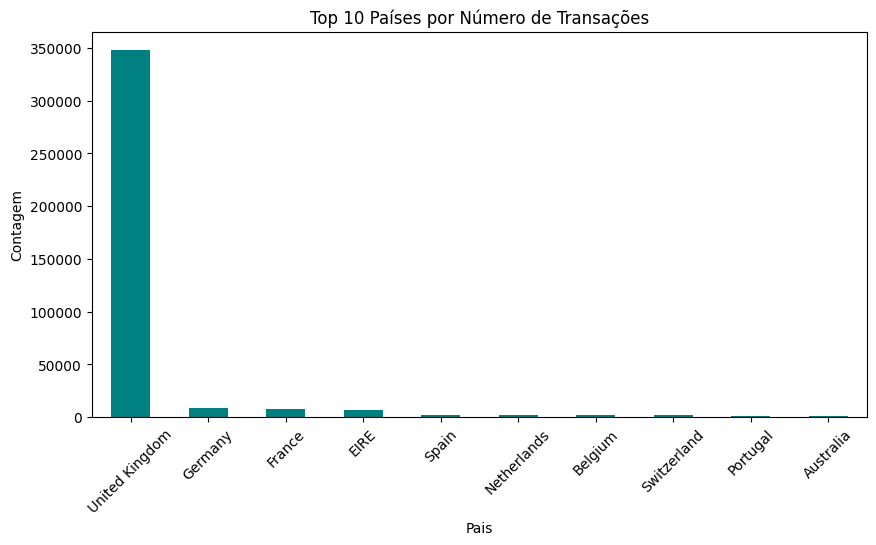

In [71]:
# Top 10 Países com mais transações
plt.figure(figsize=(10, 5))
df_limpo['Pais'].value_counts().head(10).plot(kind='bar', color='teal')
plt.title('Top 10 Países por Número de Transações')
plt.ylabel('Contagem')
plt.xticks(rotation=45)
plt.show()

**3. Engenharia de Features (Criação de Métricas de Cliente)**

Para segmentar os clientes, precisamos de transformar dados transacionais (linha a linha) em dados comportamentais (cliente a cliente).
Vamos calcular as seguintes métricas principais:
* **Recência:** Dias desde a última compra.
* **Frequência:** Quantas vezes o cliente veio à loja.
* **Monetário:** Quanto o cliente gastou no total.
* **Comportamento:** Dia/Hora preferidos e consistência de compra (Tendência).



In [38]:
import pandas as pd
import numpy as np
from scipy.stats import linregress

# 1. CORREÇÃO DA DATA:
# Usamos 'dayfirst=True' para resolver o erro "13/12/2010" que mostrou na imagem
df_limpo['Data_Fatura'] = pd.to_datetime(df_limpo['Data_Fatura'], dayfirst=True)

# 2. CORREÇÃO DO CLIENTE (O pormenor do .0):
# Convertemos para 'int' para remover o .0 (de 12346.0 para 12346)
df_limpo['Cliente'] = df_limpo['Cliente'].astype(int)

# Criar coluna de Valor Total por Linha
df_limpo['Total_Linha'] = df_limpo['Quantidade'] * df_limpo['Preco_Unitario']

# Criar colunas de tempo auxiliares
df_limpo['Mes_Ano'] = df_limpo['Data_Fatura'].dt.to_period('M')
df_limpo['Dia_Semana'] = df_limpo['Data_Fatura'].dt.day_name()
df_limpo['Hora'] = df_limpo['Data_Fatura'].dt.hour

# Definir data de referência (dia seguinte à última compra do dataset)
data_referencia = df_limpo['Data_Fatura'].max() + pd.Timedelta(days=1)

print("Configuração inicial concluída (Datas e IDs de Cliente corrigidos).")
print(df_limpo[['Cliente', 'Data_Fatura']].head()) # Para verificar o resultado visual

Configuração inicial concluída (Datas e IDs de Cliente corrigidos).
   Cliente         Data_Fatura
0    17850 2010-12-01 08:26:00
1    17850 2010-12-01 08:26:00
2    17850 2010-12-01 08:26:00
3    17850 2010-12-01 08:26:00
4    17850 2010-12-01 08:26:00


**Funções Auxiliares:**

In [39]:
def calcular_tendencia(series):
    """Calcula a inclinação da reta de gastos ao longo dos meses."""
    if len(series) < 2:
        return 0
    y = series.values
    x = np.arange(len(y))
    slope, _, _, _, _ = linregress(x, y)
    return slope

def obter_moda(series):
    """Retorna o valor mais frequente. Retorna NaN se vazio."""
    if series.mode().empty:
        return np.nan
    return series.mode().iloc[0]

print("Funções auxiliares definidas.")

Funções auxiliares definidas.


**Métricas Base (RFM e Produtos):**

In [40]:
df_base = df_limpo.groupby('Cliente').agg({
    'Data_Fatura': lambda x: (data_referencia - x.max()).days,
    'N_Fatura': 'nunique',
    'Total_Linha': 'sum',
    'SKU': 'nunique'
}).rename(columns={
    'Data_Fatura': 'Recencia',
    'N_Fatura': 'Frequencia',
    'Total_Linha': 'Monetario',
    'SKU': 'Produtos_Distintos'
})

print(f"Métricas base calculadas para {df_base.shape[0]} clientes.")
df_base.head(3)

Métricas base calculadas para 4333 clientes.


,Recencia,Frequencia,Monetario,Produtos_Distintos
Cliente,,,,
12346,326,1,77183.60,1
12347,2,7,4310.00,103
12348,75,4,1437.24,21


**Métricas de Comportamento (Intervalos e Preferências)**

In [41]:
# Criar um dataframe apenas com faturas únicas para não enviesar a moda pelos itens
df_faturas_unicas = df_limpo[['Cliente', 'N_Fatura', 'Data_Fatura', 'Dia_Semana', 'Hora']].drop_duplicates()

def media_intervalo_dias(x):
    if len(x) < 2: return 0
    return x.sort_values().diff().dt.days.mean()

df_comportamento = df_faturas_unicas.groupby('Cliente').agg({
    'Data_Fatura': media_intervalo_dias,
    'Dia_Semana': obter_moda,
    'Hora': obter_moda
}).rename(columns={
    'Data_Fatura': 'Intervalo_Medio_Dias',
    'Dia_Semana': 'Dia_Preferido',
    'Hora': 'Hora_Preferida'
})

print("Métricas de comportamento calculadas.")
df_comportamento.head(3)

Métricas de comportamento calculadas.


,Intervalo_Medio_Dias,Dia_Preferido,Hora_Preferida
Cliente,,,
12346,0.000000,Tuesday,10
12347,60.333333,Thursday,14
12348,94.000000,Tuesday,10


**Métricas de Valor Médio por Compra:**

In [42]:
# Primeiro somamos por fatura individual
df_totais_fatura = df_limpo.groupby(['Cliente', 'N_Fatura']).agg({
    'Total_Linha': 'sum',
    'Quantidade': 'sum'
}).reset_index()

# Depois fazemos a média por cliente
df_medias_compra = df_totais_fatura.groupby('Cliente').agg({
    'Total_Linha': 'mean',
    'Quantidade': 'mean'
}).rename(columns={
    'Total_Linha': 'Gasto_Medio_Por_Compra',
    'Quantidade': 'Media_Produtos_Por_Compra'
})

print("Métricas médias por compra calculadas.")
df_medias_compra.head(3)

Métricas médias por compra calculadas.


,Gasto_Medio_Por_Compra,Media_Produtos_Por_Compra
Cliente,,
12346,77183.600000,74215.000000
12347,615.714286,351.142857
12348,359.310000,583.000000


**Métricas Mensais e Tendência:**

In [43]:
# Agrupar gastos por Cliente e Mês
df_mensal = df_limpo.groupby(['Cliente', 'Mes_Ano'])['Total_Linha'].sum().reset_index()

# Aplicar funções estatísticas e a nossa função de tendência
df_tendencias = df_mensal.groupby('Cliente')['Total_Linha'].agg([
    'mean',
    'std',
    calcular_tendencia
]).rename(columns={
    'mean': 'Gasto_Medio_Mensal',
    'std': 'Desvio_Padrao_Gasto_Mensal',
    'calcular_tendencia': 'Tendencia_Compra'
}).fillna(0)

print("Métricas de tendência mensal calculadas.")
df_tendencias.head(3)

Métricas de tendência mensal calculadas.


,Gasto_Medio_Mensal,Desvio_Padrao_Gasto_Mensal,Tendencia_Compra
Cliente,,,
12346,77183.600000,0.000000,0.000000
12347,615.714286,341.070789,4.486071
12348,359.310000,203.875689,-100.884000


**Consolidação Final:**

In [69]:
# 1. Juntar todos os dataframes criados
df_clientes = pd.concat([
    df_base,
    df_comportamento,
    df_medias_compra,
    df_tendencias
], axis=1)

print(f"Dimensão inicial: {df_clientes.shape}")

# 2. REMOÇÃO DO OUTLIER EXTREMO (Cliente 12346)
# Verificamos se ele existe no índice e removemos
if 12346 in df_clientes.index:
    df_clientes = df_clientes.drop(12346)
    print("-> Cliente 12346 removido com sucesso.")

# 3. (OPCIONAL) Filtro Estatístico para outros casos extremos
# Removemos clientes que gastam mais do que 99.9% da população (para tirar erros de sistema)
limite_superior = df_clientes['Monetario'].quantile(0.999)
outliers_estatisticos = df_clientes[df_clientes['Monetario'] > limite_superior]
print(f"-> Removidos mais {len(outliers_estatisticos)} outliers estatísticos (acima de {limite_superior:.2f}€).")

df_clientes = df_clientes[df_clientes['Monetario'] < limite_superior]

# 4. Resultado Final
print("-" * 30)
print(f"Dimensão Final após limpeza: {df_clientes.shape}")
df_clientes.head()

Dimensão inicial: (4333, 12)
-> Cliente 12346 removido com sucesso.
-> Removidos mais 5 outliers estatísticos (acima de 132170.93€).
------------------------------
Dimensão Final após limpeza: (4327, 12)


,Recencia,Frequencia,Monetario,Produtos_Distintos,Intervalo_Medio_Dias,Dia_Preferido,Hora_Preferida,Gasto_Medio_Por_Compra,Media_Produtos_Por_Compra,Gasto_Medio_Mensal,Desvio_Padrao_Gasto_Mensal,Tendencia_Compra
Cliente,,,,,,,,,,,,
12347,2,7,4310.00,103,60.333333,Thursday,14,615.714286,351.142857,615.714286,341.070789,4.486071
12348,75,4,1437.24,21,94.000000,Tuesday,10,359.310000,583.000000,359.310000,203.875689,-100.884000
12349,19,1,1457.55,72,0.000000,Monday,9,1457.550000,630.000000,1457.550000,0.000000,0.000000
12350,310,1,294.40,16,0.000000,Wednesday,16,294.400000,196.000000,294.400000,0.000000,0.000000
12352,36,7,1385.74,57,43.000000,Tuesday,14,197.962857,75.142857,346.435000,120.042154,-2.682000


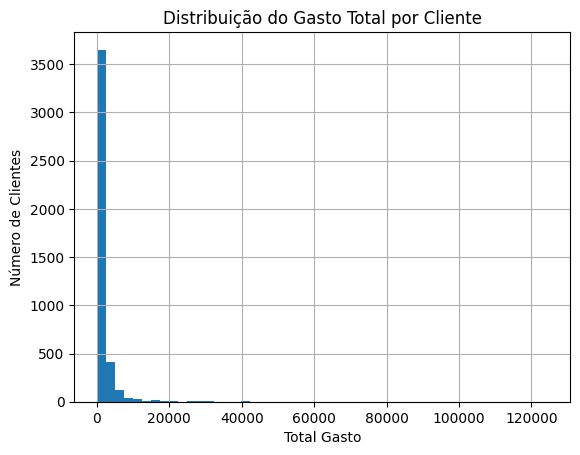

In [68]:
import matplotlib.pyplot as plt

df_clientes['Monetario'].hist(bins=50)
plt.title("Distribuição do Gasto Total por Cliente")
plt.xlabel("Total Gasto")
plt.ylabel("Número de Clientes")
plt.show()